# Project 4: Spotify — Pass 07

## Problem Definition


#### Business Problem

This project aims to predict the popularity of unreleased songs shortly following release, based on song data from Spotify's Top 200 Weekly (Global) charts from 2020 and 2021. Companies like Spotify may wish to understand and predict what types of tracks become hits and go viral, as these tracks can be promoted better and charge more for advertising.

#### Data Science Problem

Song popularity will be predicted using one of three different tree-based regression models: decision-tree, random forest, and xgboost.

Popularity is a continuous, numeric floating-point value. As such, this is a supervised regression problem, where the target of the prediction is the upcoming popularity of a prospective track release.

(Note: For passes 1-3, transactions data from Project 1 will be used. Similarly, for passes 4-6, housing data from Project 2 will be used. Passes 7-10 will utilize the spotify data particular to the above problem statement, with pass 10 having the most comprehensive use.)

In [ ]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

import requests
from google.colab import userdata
import os

## Data Collection/Sources


### Authenticate to Hugging Face


In [ ]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:3]} ... {_[-4:]}"

'hf_ ... Tuux'

In [ ]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'timnickellddds'

In [ ]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [ ]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [ ]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/spotify-numeric.parquet"
hf_url


'https://huggingface.co/datasets/timnickellddds/Data_Science-22/resolve/main/spotify-numeric.parquet'

In [ ]:
df_parquet = pd.read_parquet( hf_url )
df_parquet.shape


(1545, 11)

In [ ]:
df_parquet.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1545 entries, 0 to 1544
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Popularity        1545 non-null   int64  
 1   Artist Followers  1545 non-null   int64  
 2   Danceability      1545 non-null   float64
 3   Energy            1545 non-null   float64
 4   Loudness          1545 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 60.5 KB


## Data Cleaning


In [ ]:
df = df_parquet

Basic Cleaning/Inspection

In [ ]:
df.head()

,Popularity,Artist Followers,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence
0,100,3377762,0.714,0.800,-4.808,0.0504,0.1270,0.3590,134.002,211560,0.589
1,99,2230022,0.591,0.764,-5.484,0.0483,0.0383,0.1030,169.928,141806,0.478
2,99,6266514,0.563,0.664,-5.044,0.1540,0.3350,0.0849,166.928,178147,0.688
3,98,83293380,0.808,0.897,-3.712,0.0348,0.0469,0.3640,126.026,231041,0.591
4,96,5473565,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894


In [ ]:
df.tail()

,Popularity,Artist Followers,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence
1540,79,27167675,0.762,0.700,-6.021,0.0694,0.00261,0.1530,116.073,209320,0.608
1541,66,15019109,0.528,0.870,-3.123,0.0851,0.24000,0.3330,152.370,181930,0.714
1542,81,22698747,0.765,0.523,-4.333,0.0300,0.18400,0.1320,104.988,217307,0.394
1543,60,208630,0.832,0.550,-7.026,0.0587,0.24900,0.1820,154.064,152784,0.881
1544,70,42227614,0.448,0.603,-7.176,0.0640,0.43300,0.0862,205.272,221307,0.422


In [ ]:
df.shape

(1545, 11)

In [ ]:
df.size

16995

In [ ]:
df.describe().transpose().head()

,count,mean,std,min,25%,50%,75%,max
Popularity,1545.0,7.008932e+01,1.582403e+01,0.000,65.000,73.000,8.000000e+01,1.000000e+02
Artist Followers,1545.0,1.471690e+07,1.667579e+07,4883.000,2123734.000,6852509.000,2.269875e+07,8.333778e+07
Danceability,1545.0,6.899968e-01,1.424440e-01,0.150,0.599,0.707,7.960000e-01,9.800000e-01
Energy,1545.0,6.334951e-01,1.615770e-01,0.054,0.532,0.642,7.520000e-01,9.700000e-01
Loudness,1545.0,-6.348474e+00,2.509281e+00,-25.166,-7.491,-5.990,-4.711000e+00,1.509000e+00


In [ ]:
df.isnull().sum()*1000

,0
Popularity,0
Artist Followers,0
Danceability,0
Energy,0
Loudness,0
Speechiness,0
Acousticness,0
Liveness,0
Tempo,0
Duration (ms),0


In [ ]:
row_nulls_count = int(df.isnull().sum().sum())
row_nulls_count

0

In [ ]:
print(f"Rows containing nulls: {row_nulls_count}")

Rows containing nulls: 0


In [ ]:
# No data cleaning necessary for this pass:
# data cleaning performed in previous project pass.
# See Project 4 Pass 07a for reference.

## Exploratory Data Analysis


In [ ]:
target_col = 'Popularity'

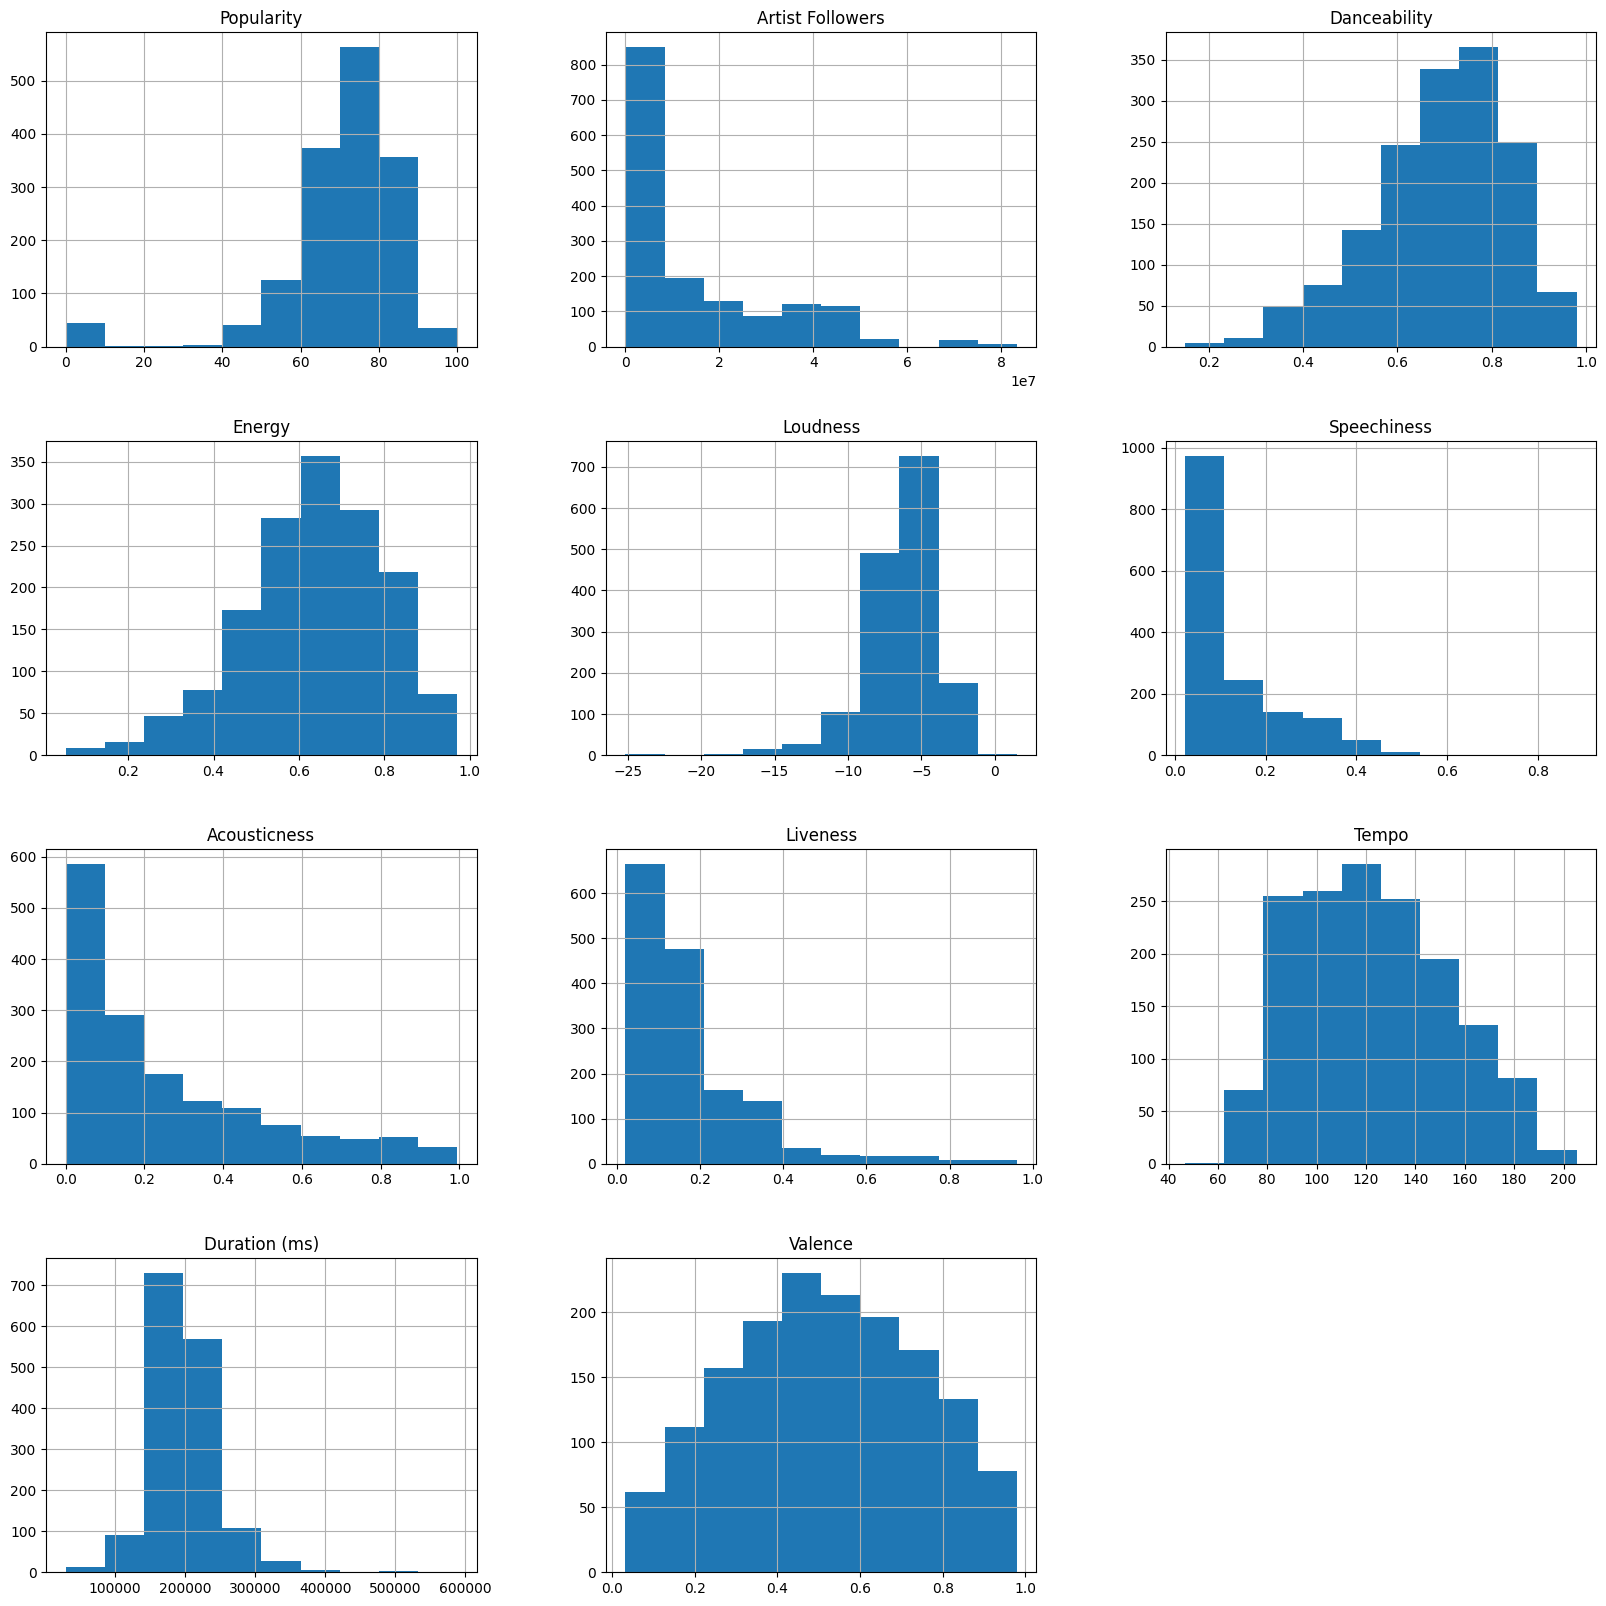

In [ ]:
# Display a histogram
df.hist(figsize=(20, 20)) ;

Text(70.72222222222221, 0.5, 'Features')

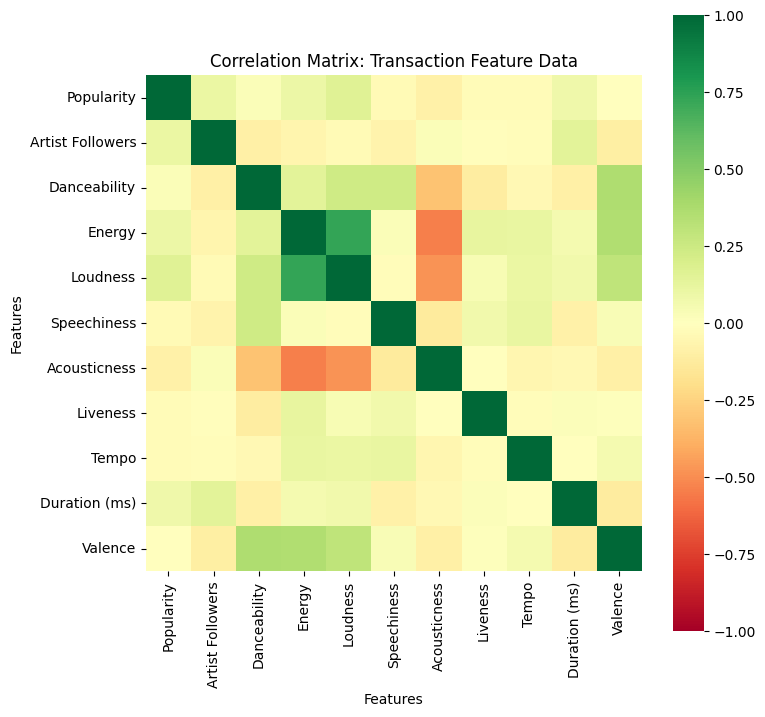

In [ ]:
# column correlations
column_correlations = df.corr()

# Display correlation matrix
plt.figure(figsize = (8, 8))
sns.heatmap(
    column_correlations,
    annot = False,
    square = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)
plt.title("Correlation Matrix: Transaction Feature Data")
plt.xlabel("Features")
plt.ylabel("Features")

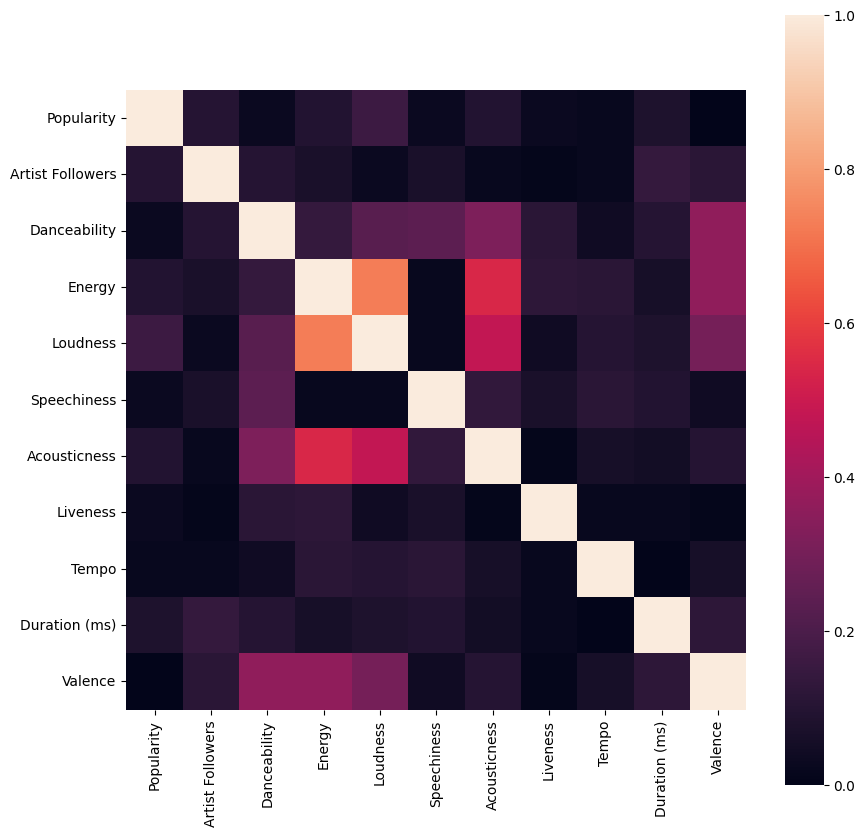

In [ ]:
# Correlation plot — target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;


In [ ]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,Popularity
Popularity,1.00
Loudness,0.16
Artist Followers,0.10
Acousticness,0.09
Energy,0.09
Duration (ms),0.08
Danceability,0.03
Speechiness,0.03
Liveness,0.03
Tempo,0.02


<Axes: >

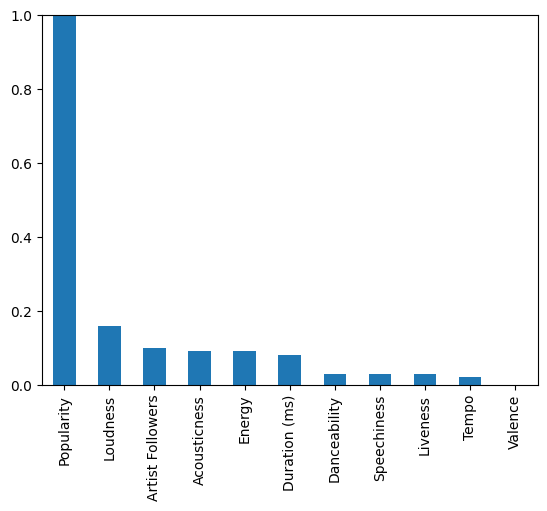

In [ ]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [ ]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,Popularity,Popularity,1.00
1,Popularity,Artist Followers,0.10
2,Popularity,Danceability,0.03
3,Popularity,Energy,0.09
4,Popularity,Loudness,0.16
...,...,...,...
116,Valence,Acousticness,0.10
117,Valence,Liveness,0.01
118,Valence,Tempo,0.06
119,Valence,Duration (ms),0.12


In [ ]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,Popularity,Artist Followers,0.10
1,Popularity,Danceability,0.03
2,Popularity,Energy,0.09
3,Popularity,Loudness,0.16
4,Popularity,Speechiness,0.03
...,...,...,...
105,Valence,Speechiness,0.04
106,Valence,Acousticness,0.10
107,Valence,Liveness,0.01
108,Valence,Tempo,0.06


In [ ]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Energy,Loudness,0.73
1,Loudness,Energy,0.73
2,Energy,Acousticness,0.54
3,Acousticness,Energy,0.54
4,Acousticness,Loudness,0.48
...,...,...,...
105,Liveness,Valence,0.01
106,Popularity,Valence,0.00
107,Tempo,Duration (ms),0.00
108,Valence,Popularity,0.00


In [ ]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Energy,Loudness,0.73
1,Energy,Acousticness,0.54
2,Acousticness,Loudness,0.48
3,Valence,Danceability,0.36
4,Energy,Valence,0.36
5,Danceability,Acousticness,0.32
6,Valence,Loudness,0.30
7,Speechiness,Danceability,0.24
8,Danceability,Loudness,0.23
9,Popularity,Loudness,0.16


## Processing



In [ ]:
target_col = 'Popularity'

### Decision Tree Regression

In [ ]:
features = df.drop(target_col, axis = 1)
target = df[target_col]
X = features
y = target

In [ ]:
# Multiple CV — loop count
n = 30

# Create array to hold results
rmses = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = DecisionTreeRegressor(max_depth = 3)  # Arbitrarily choosing max_depth of 3

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

In [ ]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(10.985811800001015)

### How do we choose the tree depth?

In [ ]:
loops_count = 30

max_depths = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
# max_depths = [2,4,6,8,10,12,14,16,18,20]
rms_depth  = np.zeros(len(max_depths))
std_depth  = np.zeros(len(max_depths))

numLoops = loops_count

for n, depth in enumerate(max_depths):
  rmses  = np.zeros(numLoops)

  for i in range(0,numLoops):
    # Train Test Split
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

    # Create an empty model
    model = DecisionTreeRegressor(max_depth = depth)  # Arbitrarily choosing max_depth of 3

    # Train ( fit ) the model
    model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = model.predict(X_test)

    # Calculate the metric and save to array
    rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

  rms_depth[n] = rmses.mean()
  std_depth[n] = rmses.std( ddof = 1 )


In [ ]:
pd.DataFrame( zip( max_depths, rms_depth, std_depth ), columns = "depth rmse STDev".split() )


,depth,rmse,STDev
0,1,15.240658,1.076843
1,2,11.175096,1.288103
2,3,10.590462,0.649294
3,4,10.987138,0.851409
4,5,11.500064,0.941666
5,6,11.660609,0.823722
6,7,12.220184,0.929397
7,8,11.989305,0.924211
8,9,12.427355,0.716868
9,10,12.688810,0.807668


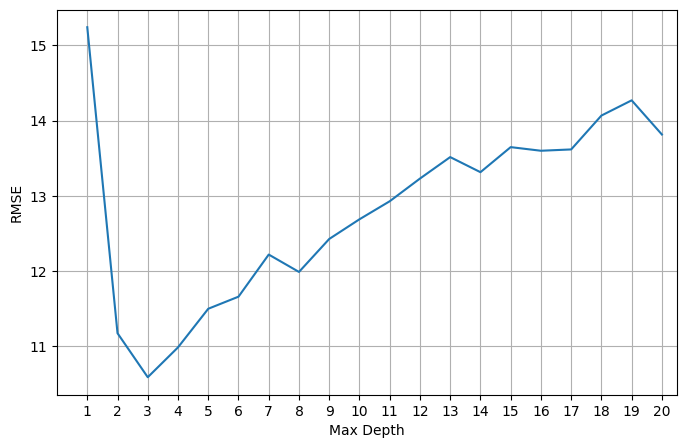

In [ ]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(max_depths, rms_depth)
plt.xlabel('Max Depth')
plt.ylabel('RMSE')
plt.xlim(0, 20.5)
plt.xticks(max_depths)
plt.grid()


RMSPE at a minimum at around depth = 3

In [ ]:
# Multiple CV — loop count
n = 30

# Depth
depth = 3

# Create array to hold results
rmses = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = DecisionTreeRegressor(max_depth = depth)  # Arbitrarily choosing max_depth of 3

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))

In [ ]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(10.925700774880823)

## Data Visualization/Communication of Results


### Visualize the Decision Tree

In [ ]:
import graphviz
from IPython.display import display
from sklearn import tree

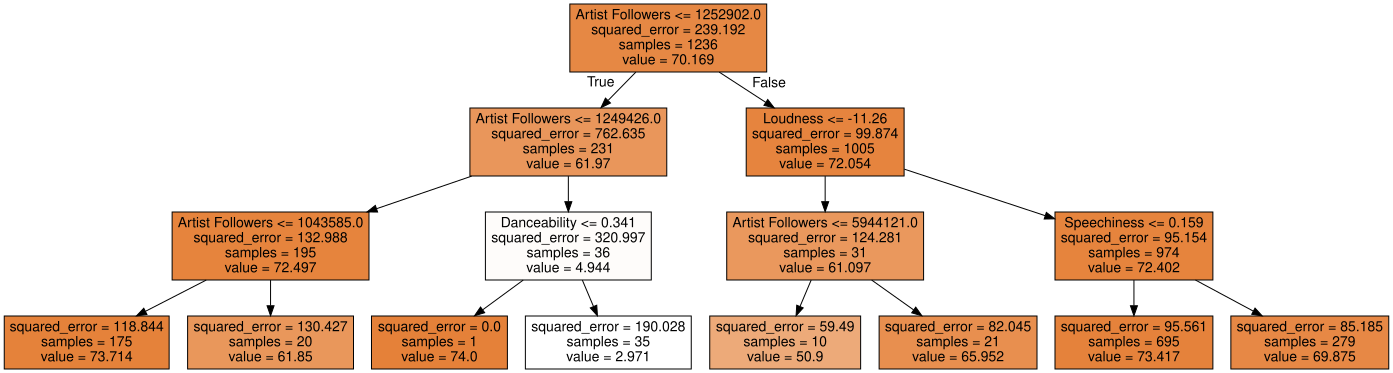

In [ ]:
# Option 1
display(
  graphviz.Source(
    tree.export_graphviz(
      model,
      feature_names = X.columns,
      filled = True,
    )
  )
)


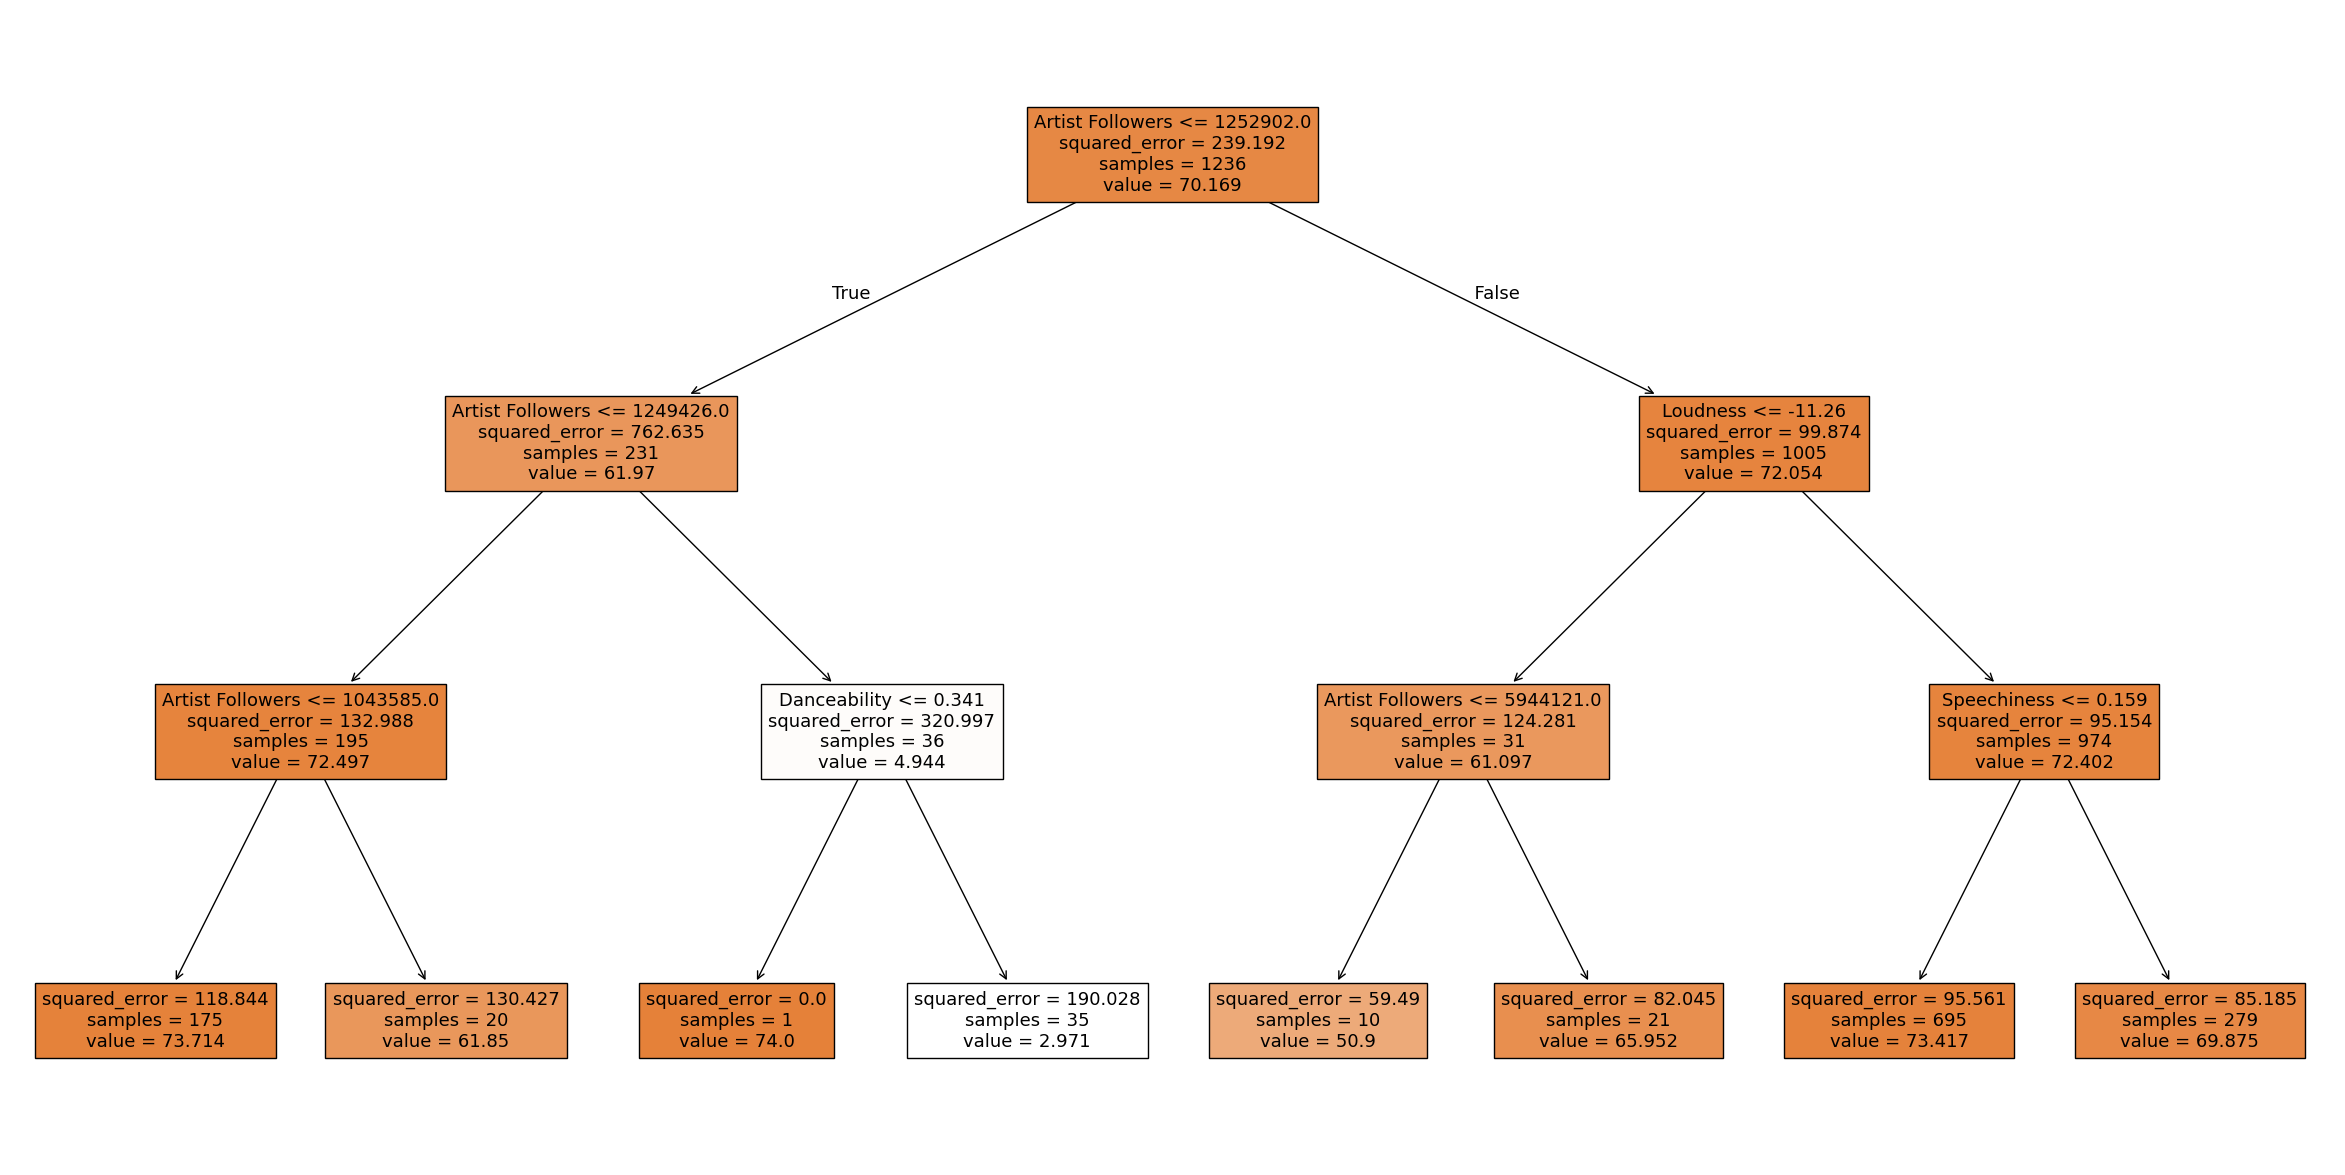

In [ ]:
# Option 2
plt.figure(figsize=(30,15))
tree_plot = tree.plot_tree(
  model,
  feature_names = X.columns,
  filled=True,
)


### Find Important Predictors

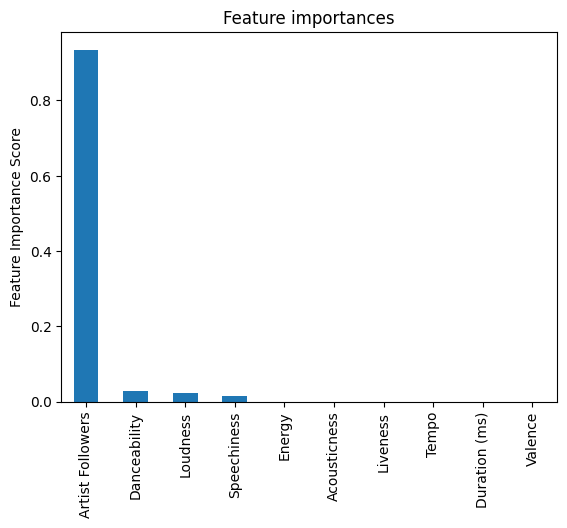

In [ ]:
importances = model.feature_importances_
tree_importances = pd.Series( importances, index = X.columns )

plt.figure()
# tree_importances.plot.bar()
tree_importances.sort_values( ascending = False ).plot.bar()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;


In [ ]:
( tree_importances.sort_values( ascending = False ) * 100 ).cumsum()


,0
Artist Followers,93.503940
Danceability,96.337760
Loudness,98.556413
Speechiness,100.000000
Energy,100.000000
Acousticness,100.000000
Liveness,100.000000
Tempo,100.000000
Duration (ms),100.000000
Valence,100.000000


### Visualize the Data

Text(0, 0.5, 'Frequency')

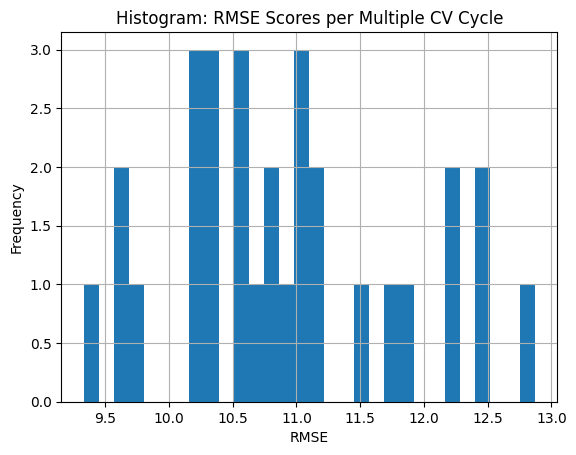

In [ ]:
# Display a histogram of the results
pd.Series(rmses).hist(bins = 30)
plt.title("Histogram: RMSE Scores per Multiple CV Cycle")
plt.xlabel("RMSE")
plt.ylabel("Frequency")

In [198]:
df[target_col].mean()

np.float64(70.08932038834952)

## Conclusions

- The best RMSE was around 10.59, occurring at a tree depth of 3.
- Decision Tree yields fairly good result: high stability (std dev at 0.649294 = under 1)
- Average song popularity = 70. For songs at this value, the model should predict somewhere between 59.4 and 80.6 (70 ± 10.59).
- Few strong signals dominate; others noise
- change in rmse with tree depth indicates meaningful signal -- real predictive patterns in data
- Relative to linear regression, Decision Tree has the advantage of not needing to meet the requirements of linear regression (features are independent from the target), and are independent from one another (not collinear).